# Notebook 1 — Datos

**Práctica 3 · Aprendizaje Automático**

Integrantes: Michael Franco, Michael Lata, Jordy Romero, Nayeli Barbecho

Este cuaderno cubre todo lo relacionado con **datos**: carga del export real de
ventas de **El Café que te Conté**, validación, ingeniería de features y
preparación de los targets multi-horizonte que usará el notebook
`02_procesos.ipynb`.

**Cambio de fuente de datos:** esta práctica arrancó sobre el dataset sintético de
la Práctica 2. Ahora que la cafetería entregó su export real (`ventas.csv`, nivel
ticket/línea, 2026-04-01 a 2026-07-31), el pipeline completo corre sobre esos datos
reales. Variables que eran sintéticas por no tener respaldo (`promocion_activa`,
`clima_lluvia`, `proporcion_stock`) se retiraron; se agregaron variables reales que
el export sí trae: precio real, tráfico de clientes real (tickets) y hora de venta.

## 1. Configuración y carga de datos crudos

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from practica3.features import (  # noqa: E402
    FEATURE_COLS, HORIZONTES, MIN_DIAS_HISTORICOS,
    agregar_targets, calidad_datos_por_producto,
    cargar_datos_crudos, construir_dataset_diario,
)

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["figure.dpi"] = 110

DATA_RAW = ROOT / "data" / "raw"
DATA_PROCESSED = ROOT / "data" / "processed"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

ventas = cargar_datos_crudos(DATA_RAW)
print(f"ventas (nivel ticket/línea): {ventas.shape}")
print(f"periodo   : {ventas['fecha'].min().date()} -> {ventas['fecha'].max().date()}")
print(f"tickets   : {ventas['id_ticket'].nunique()}")
print(f"productos : {ventas['producto'].nunique()}  | categorías: {sorted(ventas['categoria'].unique())}")
ventas.head(3)

ventas (nivel ticket/línea): (35667, 12)
periodo   : 2026-04-01 -> 2026-07-31
tickets   : 11893
productos : 33  | categorías: ['Bebidas', 'Desayunos', 'Galletas', 'Para Compartir', 'Pasteles']


,id_ticket,fecha_completa,hora_exacta,dia_de_la_semana,mes,categoria,producto,variante_o_sabor,cantidad_vendida,precio_unitario,total_linea,fecha
0,TICKET_00001240,01/04/2026,11:13,Miércoles,4,Pasteles,Cheesecake de Limón,NaN,3,4.7,14.1,2026-04-01
1,TICKET_00001241,01/04/2026,12:37,Miércoles,4,Bebidas,Gaseosas,Tropical,3,2.0,6.0,2026-04-01
2,TICKET_00001241,01/04/2026,12:37,Miércoles,4,Bebidas,Smoothies,Naranja,1,4.5,4.5,2026-04-01


## 2. Validación de datos crudos

Antes de construir features se valida que no haya nulos en las columnas que
realmente usa el pipeline, y que el rango de fechas sea el esperado — cualquier
hueco aquí se propagaría como sesgo silencioso al resto del pipeline.

`variante_o_sabor` sí tiene muchos "nulos" (pandas interpreta el texto literal
`"N/A"` del CSV como valor faltante) — pero esa columna no se usa: la agregación es
a nivel `producto`, no `producto+variante`, así que no afecta al modelo.

In [2]:
COLUMNAS_USADAS = [
    "id_ticket", "fecha", "hora_exacta", "categoria", "producto",
    "cantidad_vendida", "precio_unitario",
]
nulos_relevantes = ventas[COLUMNAS_USADAS].isnull().sum().sum()
assert nulos_relevantes == 0, f"Hay nulos en columnas usadas por el pipeline: {nulos_relevantes}"
assert (ventas["cantidad_vendida"] > 0).all(), "Hay líneas con cantidad <= 0"
assert (ventas["precio_unitario"] > 0).all(), "Hay líneas con precio <= 0"

print(f"'variante_o_sabor' sin especificar (N/A del CSV, no se usa): {ventas['variante_o_sabor'].isnull().sum()} filas")

por_producto = ventas.groupby("producto")["fecha"].nunique().sort_values()
print("Cobertura de días por producto (mín / máx):", por_producto.min(), "/", por_producto.max())
print("OK — sin nulos en columnas relevantes, cantidades y precios válidos.")

'variante_o_sabor' sin especificar (N/A del CSV, no se usa): 16263 filas
Cobertura de días por producto (mín / máx): 119 / 122
OK — sin nulos en columnas relevantes, cantidades y precios válidos.


## 3. Construcción del dataset diario y features

`construir_dataset_diario` (en `src/practica3/features.py`) agrega por (fecha,
producto) — a nivel **producto**, no producto+variante, para series más robustas —
y calcula las 24 columnas de `FEATURE_COLS`:

- **Calendario + historia temporal**: día de semana, mes, feriados, lags y medias
  móviles (7/14 días), codificación cíclica.
- **3 variables reales nuevas** (reemplazan a las sintéticas de la iteración
  anterior): `precio_promedio` (precio real ese día), `n_tickets_dia` (tráfico real
  de clientes, no estimado) y `hora_promedio_venta` (patrón horario real).

In [3]:
df = construir_dataset_diario(ventas)
print(f"dataset diario: {df.shape}  | productos: {df['product_id'].nunique()}  | features: {len(FEATURE_COLS)}")
df[["fecha", "product_id", "nombre", "categoria"] + FEATURE_COLS].head(10)

dataset diario: (4007, 28)  | productos: 33  | features: 24


,fecha,product_id,nombre,categoria,cantidad_vendida,dia_semana,mes,es_weekend,es_feriado,dias_desde_inicio,...,rolling_std_14,dia_semana_sin,dia_semana_cos,mes_sin,mes_cos,es_fecha_especial,temporada_seca,precio_promedio,n_tickets_dia,hora_promedio_venta
0,2026-04-01,1,Affo Cookie,Para Compartir,10,2,4,0,0,0,...,NaN,0.974928,-0.222521,0.866025,-0.5,0,0,4.0,105,16.963333
1,2026-04-02,1,Affo Cookie,Para Compartir,11,3,4,0,0,1,...,NaN,0.433884,-0.900969,0.866025,-0.5,0,0,4.0,115,19.391667
2,2026-04-03,1,Affo Cookie,Para Compartir,12,4,4,0,1,2,...,NaN,-0.433884,-0.900969,0.866025,-0.5,0,0,4.0,100,13.663889
3,2026-04-04,1,Affo Cookie,Para Compartir,10,5,4,1,0,3,...,NaN,-0.974928,-0.222521,0.866025,-0.5,0,0,4.0,128,12.711111
4,2026-04-05,1,Affo Cookie,Para Compartir,14,6,4,1,0,4,...,NaN,-0.781831,0.623490,0.866025,-0.5,0,0,4.0,99,12.887500
5,2026-04-06,1,Affo Cookie,Para Compartir,3,0,4,0,0,5,...,NaN,0.000000,1.000000,0.866025,-0.5,0,0,4.0,85,13.116667
6,2026-04-07,1,Affo Cookie,Para Compartir,9,1,4,0,0,6,...,NaN,0.781831,0.623490,0.866025,-0.5,0,0,4.0,69,13.443333
7,2026-04-08,1,Affo Cookie,Para Compartir,7,2,4,0,0,7,...,NaN,0.974928,-0.222521,0.866025,-0.5,0,0,4.0,59,15.608333
8,2026-04-09,1,Affo Cookie,Para Compartir,7,3,4,0,0,8,...,NaN,0.433884,-0.900969,0.866025,-0.5,0,0,4.0,64,12.895833
9,2026-04-10,1,Affo Cookie,Para Compartir,12,4,4,0,0,9,...,NaN,-0.433884,-0.900969,0.866025,-0.5,0,0,4.0,88,13.392857


## 4. EDA — demanda real por producto y categoría

In [4]:
print("Distribución de demanda (todos los productos):")
print(df["cantidad_vendida"].describe().round(2))

resumen = (
    df.groupby("nombre")["cantidad_vendida"]
    .agg(media="mean", std="std", min="min", max="max")
    .round(2)
    .sort_values("media", ascending=False)
)
print()
print("Top 10 productos por demanda diaria promedio:")
print(resumen.head(10).to_string())

Distribución de demanda (todos los productos):
count    4007.00
mean       17.81
std        13.54
min         1.00
25%         9.00
50%        14.00
75%        22.00
max       107.00
Name: cantidad_vendida, dtype: float64

Top 10 productos por demanda diaria promedio:
                      media    std  min  max
nombre                                      
Gaseosas              48.96  18.04   18   97
Café                  48.34  17.87   17  107
Jugos                 36.60  14.62    8   76
Smoothies             36.52  14.69    8   80
Agua                  26.02  10.20    3   54
Frappé                25.07  10.61    8   53
Red Velvet            24.89  10.40    6   52
Chispas de Chocolate  24.01  10.28    4   51
Pizza Toast           14.28   6.88    1   35
Maní y Almendras      13.31   6.52    1   34


### 4.1 Ventas por categoría

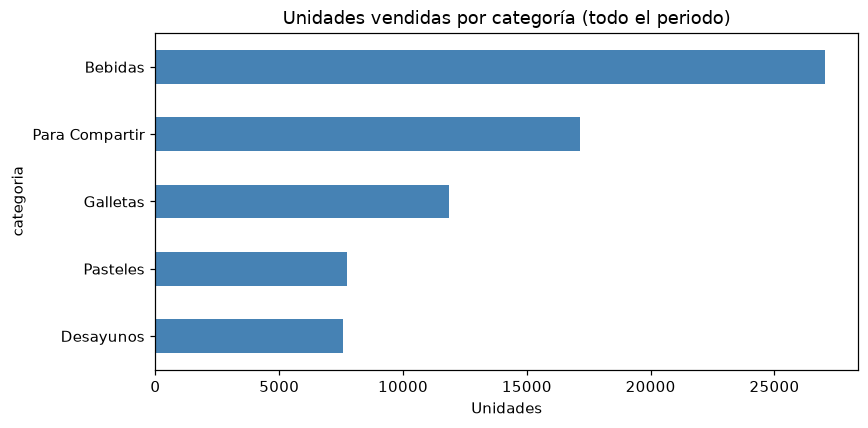

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ventas.groupby("categoria")["cantidad_vendida"].sum().sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_title("Unidades vendidas por categoría (todo el periodo)")
ax.set_xlabel("Unidades")
plt.tight_layout(); plt.show()

### 4.2 Tendencia temporal (top-2 productos)

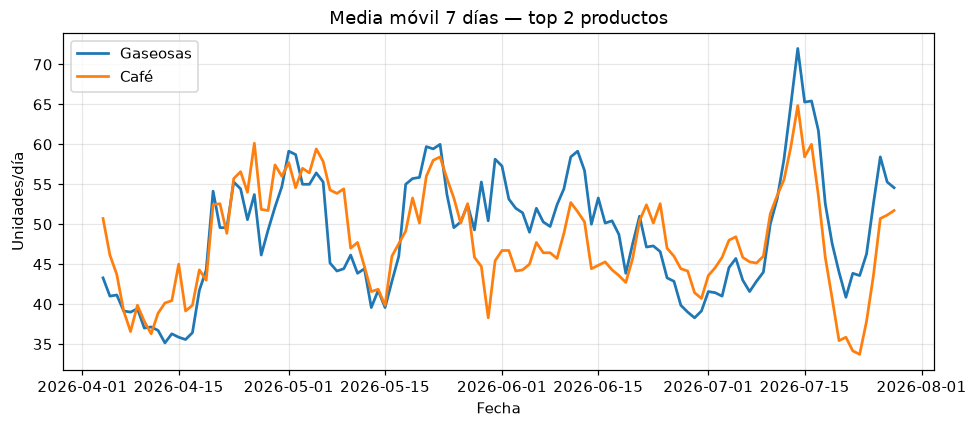

In [6]:
top2 = resumen.index[:2]
fig, ax = plt.subplots()
for nombre in top2:
    serie = df[df["nombre"] == nombre].set_index("fecha")["cantidad_vendida"]
    ax.plot(serie.index, serie.rolling(7, center=True).mean(), label=nombre, lw=1.8)
ax.set_title("Media móvil 7 días — top 2 productos")
ax.set_xlabel("Fecha"); ax.set_ylabel("Unidades/día"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 4.3 Variables reales nuevas: tráfico de clientes y patrón horario

Con datos reales aparecen señales que el dataset sintético no tenía: el número real
de tickets por día (tráfico de clientes) y la hora a la que se vende cada
categoría — útil para saber si un producto es de desayuno, media tarde, etc.

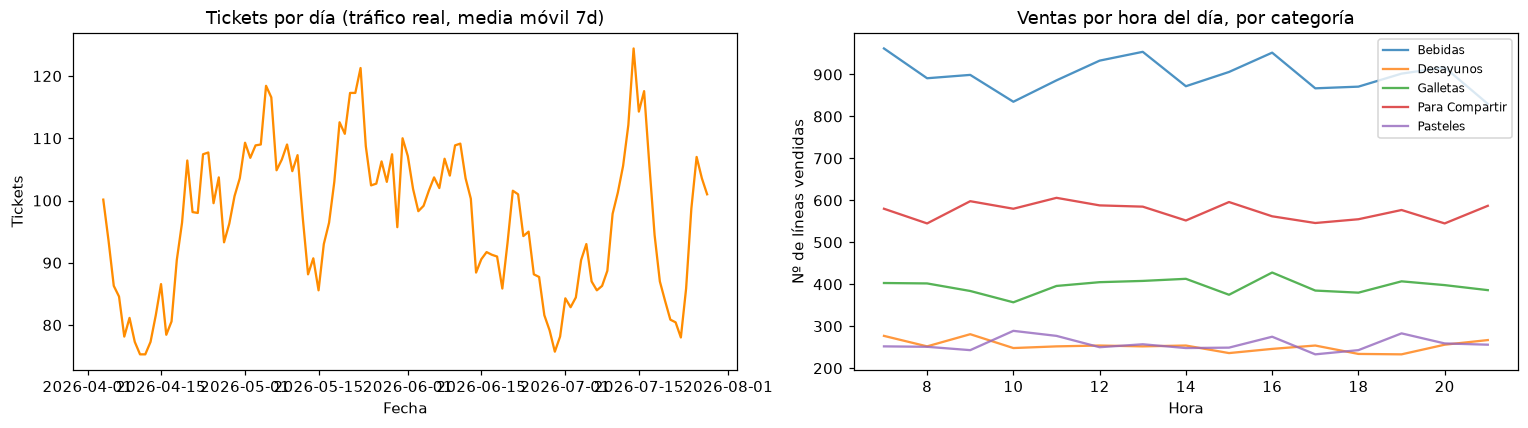

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

tickets_dia = ventas.groupby("fecha")["id_ticket"].nunique()
axes[0].plot(tickets_dia.index, tickets_dia.rolling(7, center=True).mean(), color="darkorange")
axes[0].set_title("Tickets por día (tráfico real, media móvil 7d)")
axes[0].set_xlabel("Fecha"); axes[0].set_ylabel("Tickets")

horas = pd.to_datetime(ventas["hora_exacta"], format="%H:%M").dt.hour
for cat in sorted(ventas["categoria"].unique()):
    horas[ventas["categoria"] == cat].value_counts().sort_index().plot(ax=axes[1], label=cat, alpha=0.8)
axes[1].set_title("Ventas por hora del día, por categoría")
axes[1].set_xlabel("Hora"); axes[1].set_ylabel("Nº de líneas vendidas"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Calidad de datos por producto

Punto §IV.C del feedback empresarial: el sistema debe **advertir cuando la historia
disponible es insuficiente**. Con 122 días reales y cobertura casi completa por
producto, se espera que todos pasen el umbral — pero el chequeo queda automatizado
para cuando lleguen más meses de datos con productos nuevos de menor historial.

In [8]:
calidad = calidad_datos_por_producto(df, minimo=MIN_DIAS_HISTORICOS)
print(f"umbral mínimo de días históricos: {MIN_DIAS_HISTORICOS}")
display_cols = ["product_id", "nombre", "n_dias", "fecha_min", "fecha_max", "calidad_suficiente"]
print(calidad[display_cols].to_string(index=False))

calidad.assign(
    fecha_min=lambda d: d["fecha_min"].astype(str),
    fecha_max=lambda d: d["fecha_max"].astype(str),
)[display_cols].to_json(DATA_PROCESSED / "data_quality_report.json", orient="records", indent=2)
print("\nGuardado: data/processed/data_quality_report.json")

umbral mínimo de días históricos: 30
 product_id                            nombre  n_dias  fecha_min  fecha_max  calidad_suficiente
          1                       Affo Cookie     122 2026-04-01 2026-07-31                True
          2                              Agua     122 2026-04-01 2026-07-31                True
          3                     Avocado Toast     121 2026-04-01 2026-07-31                True
          4              Bacon Egg and Cheese     122 2026-04-01 2026-07-31                True
          5                   Bananella Toast     122 2026-04-01 2026-07-31                True
          6                   Break Your Diet     122 2026-04-01 2026-07-31                True
          7                              Café     122 2026-04-01 2026-07-31                True
          8        Cheesecake de Frutos Rojos     122 2026-04-01 2026-07-31                True
          9               Cheesecake de Limón     121 2026-04-01 2026-07-31                True
   

## 6. Targets multi-horizonte

Punto §V.3 del feedback: predicciones a distintos horizontes, no solo t+1. Se
agregan `target_h1`, `target_h3` y `target_h7` (demanda del producto `h` días
después de la fila de referencia).

In [9]:
df = agregar_targets(df, HORIZONTES)
for h in HORIZONTES:
    n_validas = df[f"target_h{h}"].notna().sum()
    print(f"target_h{h}: {n_validas} filas con target válido")
df[["fecha", "product_id", "cantidad_vendida"] + [f"target_h{h}" for h in HORIZONTES]].tail(10)

target_h1: 3974 filas con target válido
target_h3: 3908 filas con target válido
target_h7: 3776 filas con target válido


,fecha,product_id,cantidad_vendida,target_h1,target_h3,target_h7
3997,2026-07-22,33,10,8.0,11.0,15.0
3998,2026-07-23,33,8,2.0,8.0,18.0
3999,2026-07-24,33,2,11.0,23.0,3.0
4000,2026-07-25,33,11,8.0,15.0,NaN
4001,2026-07-26,33,8,23.0,15.0,NaN
4002,2026-07-27,33,23,15.0,18.0,NaN
4003,2026-07-28,33,15,15.0,3.0,NaN
4004,2026-07-29,33,15,18.0,NaN,NaN
4005,2026-07-30,33,18,3.0,NaN,NaN
4006,2026-07-31,33,3,NaN,NaN,NaN


## 7. Guardado de artefactos para el notebook 2

In [10]:
df.to_parquet(DATA_PROCESSED / "dataset_features.parquet", index=False)

with open(DATA_PROCESSED / "features.json", "w") as f:
    json.dump({
        "feature_cols": FEATURE_COLS,
        "horizontes": list(HORIZONTES),
        "min_dias_historicos": MIN_DIAS_HISTORICOS,
        "n_filas": len(df),
        "n_productos": int(df["product_id"].nunique()),
        "fuente": "ventas.csv real (El Café que te Conté), 2026-04-01 a 2026-07-31",
    }, f, indent=2, ensure_ascii=False)

print("Guardado:")
print(f"  data/processed/dataset_features.parquet  ({df.shape[0]} filas x {df.shape[1]} columnas)")
print("  data/processed/features.json")

Guardado:
  data/processed/dataset_features.parquet  (4007 filas x 31 columnas)
  data/processed/features.json


## 8. Checklist de validación

In [11]:
checks = [
    ("Datos crudos cargados sin nulos (columnas usadas)", ventas[COLUMNAS_USADAS].isnull().sum().sum() == 0),
    ("Dataset diario construido", len(df) > 0),
    ("24 features calculadas", len(FEATURE_COLS) == 24),
    ("Variables reales nuevas presentes",
     {"precio_promedio", "n_tickets_dia", "hora_promedio_venta"}.issubset(df.columns)),
    ("Codificación cíclica presente", {"dia_semana_sin", "mes_cos"}.issubset(df.columns)),
    ("Calidad de datos por producto calculada", len(calidad) == df["product_id"].nunique()),
    ("Targets multi-horizonte generados", all(f"target_h{h}" in df.columns for h in HORIZONTES)),
    ("Parquet procesado guardado", (DATA_PROCESSED / "dataset_features.parquet").exists()),
]
for nombre, ok in checks:
    print(("[OK] " if ok else "[FALTA] ") + nombre)
assert all(ok for _, ok in checks), "Hay checks pendientes"


[OK] Datos crudos cargados sin nulos (columnas usadas)
[OK] Dataset diario construido
[OK] 24 features calculadas
[OK] Variables reales nuevas presentes
[OK] Codificación cíclica presente
[OK] Calidad de datos por producto calculada
[OK] Targets multi-horizonte generados
[OK] Parquet procesado guardado


## Conclusiones

- Se reemplazó el dataset sintético por el **export real de ventas de El Café que
  te Conté** (122 días, 33 productos, 5 categorías) sin cambiar la arquitectura del
  pipeline — la misma función `construir_dataset_diario` ahora produce **24
  features** a partir de datos reales.
- Se retiraron 3 variables sintéticas sin respaldo real (`proporcion_stock`,
  `promocion_activa`, `clima_lluvia`) y se agregaron 3 variables genuinamente
  reales (`precio_promedio`, `n_tickets_dia`, `hora_promedio_venta`).
- Calidad de datos por producto y targets multi-horizonte quedan igual que en la
  iteración sintética — el resto del pipeline (`02_procesos`, `03_resultados`, la
  API) no necesita cambios de diseño, solo reentrenar sobre datos reales.